# Task 1: PCA — Dimensionality Reduction

Original shape: (150, 4)
Reduced shape: (150, 2)
Explained variance ratio: [0.72962445 0.22850762]
Total explained variance: 0.9581320720000166


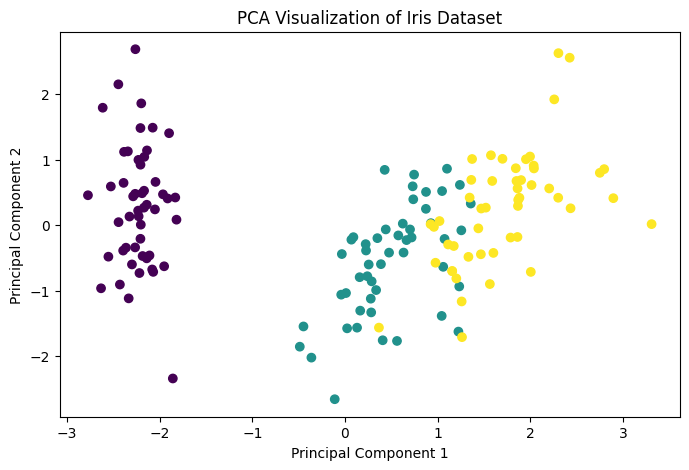

In [1]:

# Task 1: PCA

import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Load data
iris = load_iris()
X = iris.data
y = iris.target

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply PCA: reduce 4 features to 2 components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Original shape:", X.shape)
print("Reduced shape:", X_pca.shape)
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total explained variance:",
      pca.explained_variance_ratio_.sum())

# Plot PCA result
plt.figure(figsize=(8, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of Iris Dataset")
plt.show()


# Task 2: Feature Engineering

In [2]:

# Task 2: Feature Engineering

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Create sample dataset
df = pd.DataFrame({
    "age": [20, 25, 30, 35, 40, 45, 50, 55, 60, 65],
    "income": [20000, 25000, 30000, 35000, 40000,
               45000, 50000, 55000, 60000, 65000],
    "spending": [5000, 7000, 8000, 9000, 12000,
                 13000, 15000, 17000, 18000, 20000],
    "purchased": [0, 0, 0, 0, 0, 1, 1, 1, 1, 1]
})

# Create new features
df["income_per_age"] = df["income"] / df["age"]
df["spending_ratio"] = df["spending"] / df["income"]

print(df.head())

# Separate features and target
X = df.drop("purchased", axis=1)
y = df["purchased"]

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Scale features and train model
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression()
model.fit(X_train_scaled, y_train)

predictions = model.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, predictions))


   age  income  spending  purchased  income_per_age  spending_ratio
0   20   20000      5000          0          1000.0        0.250000
1   25   25000      7000          0          1000.0        0.280000
2   30   30000      8000          0          1000.0        0.266667
3   35   35000      9000          0          1000.0        0.257143
4   40   40000     12000          0          1000.0        0.300000
Accuracy: 1.0


# Task 3: Imbalanced Data — SMOTE

In [5]:

# Task 3: Handle Imbalanced Data with SMOTE

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

# Create imbalanced dataset
X, y = make_classification(
    n_samples=1000,
    n_features=10,
    weights=[0.90, 0.10],
    random_state=42
)

print("Original class distribution:", __import__("numpy").bincount(y))

# Split before applying SMOTE
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# SMOTE only on training data through pipeline
model = Pipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)
predictions = model.predict(X_test)

print("\nClassification Report:")
print(classification_report(y_test, predictions))


Original class distribution: [897 103]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.90      0.95       179
           1       0.54      1.00      0.70        21

    accuracy                           0.91       200
   macro avg       0.77      0.95      0.82       200
weighted avg       0.95      0.91      0.92       200



# Task 4: Data Leakage

In [6]:

# Task 4: Prevent Data Leakage using Pipeline

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Load data
data = load_breast_cancer()
X, y = data.data, data.target

# Split data FIRST
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Safe pipeline
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=5000)
)

# Fit preprocessing and model only on training data
model.fit(X_train, y_train)

# Predict on unseen test data
predictions = model.predict(X_test)

print("Test Accuracy:", accuracy_score(y_test, predictions))


Test Accuracy: 0.9824561403508771


# Task 5: ML Pipeline with Cross-Validation

In [7]:

# Task 5: Pipeline + Cross Validation

from sklearn.datasets import load_iris
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC

# Load data
iris = load_iris()
X, y = iris.data, iris.target

# Create pipeline
model = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=1.0)
)

# 5-fold cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(
    model, X, y,
    cv=cv,
    scoring="accuracy"
)

print("Fold Scores:", scores)
print("Mean Accuracy:", scores.mean())
print("Standard Deviation:", scores.std())


Fold Scores: [1.         0.96666667 0.9        1.         0.93333333]
Mean Accuracy: 0.96
Standard Deviation: 0.038873012632301994


# Task 6: Customer Segmentation using K-Means

    Annual_Income  Spending_Score  Cluster
0              15              20        2
1              16              22        2
2              17              25        2
3              18              23        2
4              20              28        2
5              40              45        0
6              42              48        0
7              45              50        0
8              47              52        0
9              50              55        0
10             75              75        1
11             78              78        1
12             80              80        1
13             85              85        1
14             90              90        1


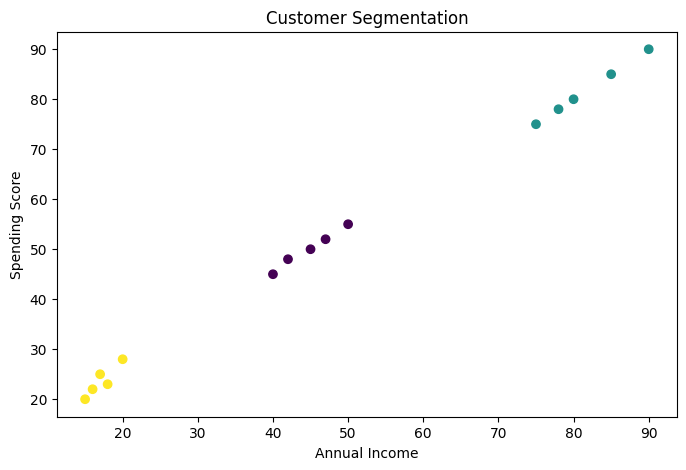

In [8]:

# Task 6: Customer Segmentation

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Sample customer dataset
df = pd.DataFrame({
    "Annual_Income": [
        15, 16, 17, 18, 20,
        40, 42, 45, 47, 50,
        75, 78, 80, 85, 90
    ],
    "Spending_Score": [
        20, 22, 25, 23, 28,
        45, 48, 50, 52, 55,
        75, 78, 80, 85, 90
    ]
})

# Select features
X = df[["Annual_Income", "Spending_Score"]]

# Scale data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Fit K-Means
model = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df["Cluster"] = model.fit_predict(X_scaled)

print(df)

# Visualize segments
plt.figure(figsize=(8, 5))
plt.scatter(
    df["Annual_Income"],
    df["Spending_Score"],
    c=df["Cluster"]
)
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.title("Customer Segmentation")
plt.show()
